# The perceptron algorithm against gradient descent

Compares the perceptron algorithm with gradient descent on mean logistic loss, on the pinwheel datasets of `separability.ipynb`.

Output: `pinwheel_percep.pdf`, with three panels on the separable dataset $(a,b)=(-2.5,1.1)$: (a) the regions of the perceptron weight at termination, (b) those of the gradient descent weight at the first step that separates the data, and (c) the norm $\|W_n\|$ under gradient descent for $b=1.1$ and $b=1.3$.

The first cell imports `separability.ipynb`, which must be in the same folder, as a module. That runs it, including its gradient descent, and takes about half a minute. `%%capture` hides its printed output and figure; the import runs only once per kernel session.

In [1]:
%%capture
import import_ipynb
from separability import *

## The perceptron algorithm

For a sample $x$ in class $i$ mismatched by $W$, the perceptron algorithm takes the step

$$W^+ = W - t\,(e_j-e_i)\otimes\tilde x,\qquad y_j=\max_{j\ne i} y_j,$$

that is, it adds $t\tilde x$ to row $i$ and subtracts it from row $j$, so the weight stays centered. Starting from $W_0=0$, the samples are swept in order, updating at each mismatched sample, until a full sweep finds no mismatch. Since $J_0(tW)=tJ_0(W)$, the learning rate $t$ does not affect the number of updates; we take $t=1$.

In [2]:
def perceptron(X, y, t=1.0, max_updates=200_000):
    "Return (W, number of updates, number of sweeps, converged, seconds)."
    W = np.zeros((y.max() + 1, X.shape[1]))
    n = sweeps = 0
    t0 = perf_counter()
    while n < max_updates:
        sweeps += 1
        clean = True
        for k in range(len(X)):
            yk = W @ X[k]
            i = y[k]
            z = yk.copy(); z[i] = -np.inf
            j = int(np.argmax(z))
            if yk[i] <= yk[j]:                 # x_k is mismatched
                W[i] += t*X[k]
                W[j] -= t*X[k]
                n += 1
                clean = False
        if clean:
            return W, n, sweeps, True, perf_counter() - t0
    return W, n, sweeps, False, perf_counter() - t0

## How much faster?

For each separable dataset, compare the perceptron algorithm run to termination, gradient descent at its first separating step, and the full $2\times10^5$ gradient descent steps. A gradient descent step evaluates all $N$ samples, while the perceptron algorithm evaluates one sample at a time, so *sample evaluations* is the fair unit of work. Wall-clock times depend on the machine and on the implementation: gradient descent is vectorized, the perceptron loop is plain Python.

In [3]:
perc = {}
for (a, b), r in runs.items():
    X, y = r['X'], r['y']
    N = len(X)
    if not r['separable']:
        W, updates, sweeps, converged, sec = perceptron(X, y, max_updates=20_000)
        print(f"(a,b) = ({a}, {b}): perceptron converged = {converged} after {updates} updates "
              f"({sweeps} sweeps); {int(mismatched(W, X, y).sum())} of {N} samples still mismatched")
        continue
    W, updates, sweeps, converged, sec = perceptron(X, y)
    perc[(a, b)] = dict(W=W, updates=updates)
    n_sep, W_sep, sec_sep = r['sep']
    n_all = int(r['norms'][-1, 0])
    print(f"(a,b) = ({a}, {b})")
    print(f"   {'':34s}{'steps':>9s}{'sample evals':>14s}{'seconds':>9s}{'margin':>10s}")
    print(f"   {'perceptron, to termination':34s}{updates:>9d}{sweeps*N:>14d}{sec:>9.3f}{margin(W, X, y):>10.1e}")
    print(f"   {'gradient descent, first separation':34s}{n_sep:>9d}{n_sep*N:>14d}{sec_sep:>9.3f}{margin(W_sep, X, y):>10.1e}")
    print(f"   {'gradient descent, n = 2e5':34s}{n_all:>9d}{n_all*N:>14d}{r['seconds']:>9.3f}{margin(r['W'], X, y):>10.1e}")
    print(f"   to first separation, gradient descent / perceptron: {n_sep/updates:.3g} x the steps, "
          f"{n_sep/sweeps:.3g} x the sample evaluations")
    r2 = np.max(np.sum(X[:, :2]**2, 1)); gam = margin(r['W'], X, y)
    print(f"   convergence theorem: n <= 2(1+r^2)/gamma^2 = {2*(1 + r2)/gam**2:.0f}, "
          f"with r^2 = {r2:.2f}, gamma = {gam:.4f} from the gradient descent weight")
    print()

(a,b) = (-2, 0.3)
                                         steps  sample evals  seconds    margin
   perceptron, to termination                8           792    0.003   5.2e-02
   gradient descent, first separation        1           264    0.000   5.4e-02
   gradient descent, n = 2e5            200000      52800000    4.615   4.0e-01
   to first separation, gradient descent / perceptron: 0.125 x the steps, 0.333 x the sample evaluations
   convergence theorem: n <= 2(1+r^2)/gamma^2 = 78, with r^2 = 5.09, gamma = 0.3951 from the gradient descent weight

(a,b) = (-2.5, 1.1)
                                         steps  sample evals  seconds    margin
   perceptron, to termination              160          7128    0.013   1.7e-03
   gradient descent, first separation     6128       1617792    0.231   1.0e-06
   gradient descent, n = 2e5            200000      52800000    4.775   2.3e-02
   to first separation, gradient descent / perceptron: 38.3 x the steps, 227 x the sample evaluatio

## Figure

Both methods are stopped as soon as they separate the data: the perceptron algorithm at termination, gradient descent at its first separating step. Panel (c) shows what happens if gradient descent is not stopped: on the separable dataset $\|W_n\|$ never stops growing, while on the dataset that is not separable it levels off at the minimizer. `KEY` selects the dataset for panels (a) and (b).

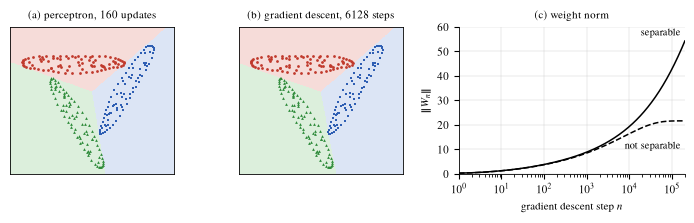

In [4]:
KEY = (-2.5, 1.1)
r, p = runs[KEY], perc[KEY]
n_sep, W_sep, _ = r['sep']

fig, axs = plt.subplots(1, 3, figsize=(6.9, 2.1), gridspec_kw={'width_ratios': [1, 1, 1.25]})
regions(axs[0], r['C'], p['W'], f"(a) perceptron, {p['updates']} updates")
regions(axs[1], r['C'], W_sep, f"(b) gradient descent, {n_sep} steps")

ax = axs[2]
for key, ls, lab, yoff in [((-2.5, 1.1), '-', 'separable', 4), ((-2.5, 1.3), '--', 'not separable', -20)]:
    n = runs[key]['norms']
    ax.plot(n[:, 0], n[:, 1], ls=ls, c='k', lw=1.1)
    ax.annotate(lab, (n[-1, 0], n[-1, 1]), xytext=(-3, yoff), textcoords='offset points',
                ha='right', fontsize=7.5)
ax.set_xscale('log')
ax.set_xlabel('gradient descent step $n$'); ax.set_ylabel(r'$\|W_n\|$')
ax.set_title('(c) weight norm', fontsize=8)
ax.grid(True, which='major', lw=0.3, color='#cccccc'); ax.set_axisbelow(True)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.set_ylim(0, 60); ax.set_xlim(1, 2e5)

plt.tight_layout(pad=0.3, w_pad=0.8)
plt.savefig('pinwheel_percep.pdf', bbox_inches='tight', pad_inches=0.02)
plt.show()